Specificity: Computes the Kalman filter on IV. It also does training on quotes and testing on trades. Results+evaluations plotted. 

In [1]:
import os
import sys
from datetime import date, datetime

# import torch
# from torch.func import jacrev
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import polars as pl
import polars.selectors as cs
import pytz

project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")

if project_root not in sys.path:
    sys.path.insert(0, project_root)


os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"  # better set these to environment variables
os.environ["QUANTDATA_TRAINING_DATA"] = (
    "!/quantdata/training"  # better set these to environment variables
)
os.environ["QUANTDATA_PROCESSING_DATA"] = (
    "!/quantdata/processing"  # better set these to environment variables
)
os.environ["QUANTDATA_CACHE_MODE"] = "on"  # turns off global cache mode
os.environ["QUANTDATA_TEST_MODE"] = "0"
import importlib as imp

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

from datetime import date

sys.path.insert(
    0, os.path.join(os.path.dirname(os.path.abspath("__file__")), "..", "shared_functions")
)


import arbitrage
import black_scholes
import ekf
import events
from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context

import personal.shared_functions.kalman_filters as kalman_filters
import personal.shared_functions.plots as plots
import personal.shared_functions.utils as utils
from personal.shared_functions.iv_evaluation import evaluate_kalman_iv
from quantdata.massive.client import MassiveClient
from quantdata.massive.taq import TAQMatchConfig, match_taq

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


In [2]:
df_tickers = pl.read_csv("../spy_options_tickers.csv")

In [3]:
trade_date = date(2024, 1, 3)
client = MassiveClient()
df_spy = client.fetch_trades("SPY", trade_date)

In [4]:
# Single call — processes all calls and puts in one batched IV computation.
# is_call column in the output distinguishes the two types.
df_quote_result, df_trade_result = kalman_filters.build_iv_surface(
    df_tickers=df_tickers,
    trade_date=trade_date,
    df_spy=df_spy,
    min_trades=100,
    simple=False,
    # discount_factor_clip=(0.999, 1.001),  # equivalent of unclipped
)

O:SPY240105C00469000: dropping 2 bad quotes (crossed×2 (first=2024-01-03 11:49:45.633413-05:00))
O:SPY240105C00472000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 15:51:02.275318-05:00))
O:SPY240105C00473000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:29:17.744517-05:00))
O:SPY240105C00474000: dropping 4 bad quotes (crossed×4 (first=2024-01-03 10:25:56.925706-05:00))
O:SPY240105C00475000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 14:02:06.496803-05:00))
O:SPY240105C00477000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:00:44.569057-05:00))
O:SPY240105C00481000: dropping 46 bad quotes (sub-tick bid×46 (first=2024-01-03 16:00:02.443177-05:00))
O:SPY240105C00482000: dropping 64 bad quotes (sub-tick bid×64 (first=2024-01-03 10:00:01.421753-05:00))
O:SPY240105C00483000: dropping 842 bad quotes (sub-tick bid×842 (first=2024-01-03 09:30:00.060278-05:00), zero bid size×1 (first=2024-01-03 09:30:00.060278-05:00))
O:SPY240105C00484000: dropping 2129 bad quotes

In [5]:
df_quote_result

ts_ns,observed_iv,bid_iv,ask_iv,kalman_iv,bid_price,ask_price,forward,discount_factor,kalman_price,strike,is_call
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
2024-01-03 09:30:00.006736128 EST,0.140982,0.138439,0.143359,0.140982,0.04,0.05,470.43,null,0.045034,481.0,true
2024-01-03 09:30:00.006781440 EST,0.13695,0.134075,0.139497,0.13695,0.09,0.11,470.43,null,0.100363,479.0,true
2024-01-03 09:30:00.007484160 EST,0.143359,0.132705,0.15164,0.143354,0.03,0.07,470.43,null,0.050011,481.0,true
2024-01-03 09:30:00.008294144 EST,0.127732,0.126371,0.129092,0.127732,2.17,2.21,470.43,null,2.189967,471.0,false
2024-01-03 09:30:00.008340992 EST,0.138195,0.131123,0.144509,0.138193,0.08,0.13,470.43,null,0.105011,479.0,true
…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:59.881741568 EST,0.134535,0.134132,0.134856,0.134535,1.88,1.89,469.055,1.0,1.885548,469.0,true
2024-01-03 16:14:59.884593152 EST,0.138451,0.132675,0.144803,0.138453,5.28,5.38,469.055,1.0,5.326722,474.0,false
2024-01-03 16:14:59.884598272 EST,0.13324,0.131454,0.136743,0.133241,3.66,3.72,469.055,1.0,3.680191,472.0,false


In [6]:
df_quote_result["discount_factor"].describe()

statistic,value
str,f64
"""count""",2.193119e6
"""null_count""",50.0
"""mean""",1.000192
"""std""",0.001662
"""min""",0.998
"""25%""",0.998
"""50%""",1.0
"""75%""",1.002
"""max""",1.002


In [7]:
df_quote_result["forward"].describe()

statistic,value
str,f64
"""count""",2.193169e6
"""null_count""",0.0
"""mean""",470.107394
"""std""",0.564447
"""min""",468.53
"""25%""",469.746493
"""50%""",470.037924
"""75%""",470.543912
"""max""",471.479042


In [8]:
# statistic	value
# str	f64
# "count"	2.193169e6
# "null_count"	0.0
# "mean"	470.106796
# "std"	0.564421
# "min"	468.53
# "25%"	469.745
# "50%"	470.039216
# "75%"	470.542289
# "max"	471.470588

In [9]:
df_trade_result

ts_ns,observed_iv,bid_iv,ask_iv,bid_price,ask_price,kalman_matched,trade_residual,kalman_price,strike,is_call
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
2024-01-03 09:30:00.031 EST,0.130745,0.130745,0.1441,0.08,0.13,0.13765,-0.006905,0.104434,479.0,true
2024-01-03 09:30:00.051 EST,0.142976,0.139489,0.142976,0.07,0.08,0.139871,0.003105,0.071086,480.0,true
2024-01-03 09:30:00.059 EST,0.153329,0.01,0.1651,0.0,0.05,null,null,NaN,483.0,true
2024-01-03 09:30:00.102 EST,0.154323,0.149303,0.151009,0.22,0.23,0.150466,0.003857,0.226927,463.0,false
2024-01-03 09:30:00.102 EST,0.141628,0.141628,0.143618,0.57,0.59,0.141883,-0.000255,0.572613,466.0,false
…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:55.650 EST,0.137266,0.136469,0.137266,1.03,1.04,0.136871,0.000395,1.035049,467.0,false
2024-01-03 16:14:56.139 EST,0.13631,0.134822,0.13631,1.38,1.4,0.135455,0.000855,1.388353,468.0,false
2024-01-03 16:14:56.139 EST,0.13631,0.134822,0.13631,1.38,1.4,0.135455,0.000855,1.388353,468.0,false


In [10]:
df_trade_result = df_trade_result.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
print(f"{df_trade_result.shape[0]:,} rows with no nulls / NaNs out of {df_trade_result.shape[0]:,}")

74,410 rows with no nulls / NaNs out of 74,410


In [11]:
df_trade_result.select(pl.col("trade_residual") ** 2).mean() * 100000

trade_residual
f64
0.719106


## Quptes smile

In [12]:
import personal.shared_functions.utils as _u

df_iv_surface_long = df_quote_result
df_iv_surface_wide = utils.synchronize_iv_surface(df_iv_surface_long)
df_filtered = df_iv_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)

strikes_all = sorted(df_iv_surface_long["strike"].unique().to_list())
strikes_C = sorted(df_iv_surface_long.filter(pl.col("is_call"))["strike"].unique().to_list())
strikes_P = sorted(df_iv_surface_long.filter(~pl.col("is_call"))["strike"].unique().to_list())

_, expiry, _ = _u.parse_option_ticker(
    df_tickers.filter(pl.col("ticker").str.contains("C"))["ticker"][0]
)

row_idx = df_filtered.shape[0] // 2  # ← change this (0 to df_filtered.shape[0]-1)
snapshot_ts = df_filtered["ts_ns"][row_idx]
row = df_iv_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"kalman_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines+markers",
        name="calls — kalman mid",
        line=dict(color="royalblue"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"bid_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — bid",
        line=dict(color="royalblue", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"ask_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — ask",
        line=dict(color="royalblue", dash="dot"),
    )
)

fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"kalman_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines+markers",
        name="puts — kalman mid",
        line=dict(color="firebrick"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"bid_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — bid",
        line=dict(color="firebrick", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"ask_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — ask",
        line=dict(color="firebrick", dash="dot"),
    )
)

fig.update_layout(
    title=f"IV smile (calls + puts) — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

In [13]:
diffs = []
for i in set(strikes_C) & set(strikes_P):
    spread = max(
        row[f"ask_iv_{int(i)}_C"][0] - row[f"bid_iv_{int(i)}_C"][0],
        row[f"ask_iv_{int(i)}_P"][0] - row[f"bid_iv_{int(i)}_P"][0],
    )
    diff = (
        abs(row[f"kalman_iv_{int(i)}_C"][0] - row[f"kalman_iv_{int(i)}_P"][0]) / spread
    )  # absolute difference between call and put IV for the same strike
    diffs.append(diff)
print(np.mean(np.square(diffs)))

0.4023611357965849


In [14]:
row

ts_ns,bid_iv_450_P,ask_iv_450_P,kalman_iv_450_P,bid_iv_454_C,ask_iv_454_C,kalman_iv_454_C,bid_iv_458_P,ask_iv_458_P,kalman_iv_458_P,bid_iv_459_P,ask_iv_459_P,kalman_iv_459_P,bid_iv_460_P,ask_iv_460_P,kalman_iv_460_P,bid_iv_461_P,ask_iv_461_P,kalman_iv_461_P,bid_iv_462_P,ask_iv_462_P,kalman_iv_462_P,bid_iv_462_P_right,ask_iv_462_P_right,kalman_iv_462_P_right,bid_iv_463_P,ask_iv_463_P,kalman_iv_463_P,bid_iv_464_P,ask_iv_464_P,kalman_iv_464_P,bid_iv_465_P,ask_iv_465_P,kalman_iv_465_P,bid_iv_465_C,ask_iv_465_C,kalman_iv_465_C,…,bid_iv_475_C,ask_iv_475_C,kalman_iv_475_C,bid_iv_476_P,ask_iv_476_P,kalman_iv_476_P,bid_iv_476_C,ask_iv_476_C,kalman_iv_476_C,bid_iv_477_P,ask_iv_477_P,kalman_iv_477_P,bid_iv_477_C,ask_iv_477_C,kalman_iv_477_C,bid_iv_478_C,ask_iv_478_C,kalman_iv_478_C,bid_iv_479_C,ask_iv_479_C,kalman_iv_479_C,bid_iv_480_C,ask_iv_480_C,kalman_iv_480_C,bid_iv_481_C,ask_iv_481_C,kalman_iv_481_C,bid_iv_482_C,ask_iv_482_C,kalman_iv_482_C,bid_iv_483_C,ask_iv_483_C,kalman_iv_483_C,bid_iv_484_C,ask_iv_484_C,kalman_iv_484_C,forward
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 12:56:18.293149440 EST,0.236685,0.248672,0.243413,0.01,0.273549,0.17395,0.172201,0.177247,0.174344,0.165424,0.169757,0.167362,0.159988,0.1634,0.161179,0.154205,0.157111,0.155385,0.150253,0.152563,0.151383,0.147723,0.149808,0.148966,0.146179,0.14804,0.147548,0.143969,0.145458,0.144839,0.142397,0.1436,0.142837,0.137843,0.147514,0.142756,…,0.132017,0.133138,0.132612,0.138542,0.152268,0.145592,0.132377,0.133786,0.133254,0.149283,0.165851,0.15787,0.132924,0.134727,0.133696,0.132762,0.135278,0.134581,0.13416,0.137444,0.136379,0.138252,0.14253,0.140345,0.138569,0.144538,0.142302,0.141504,0.149702,0.146736,0.157122,0.166098,0.159207,0.149233,0.157785,0.151116,470.32


In [15]:
spy_mid = df_spy.filter(pl.col("ts_ns") <= snapshot_ts)["price"][-1]

otm_strikes = sorted(set(strikes_C) | set(strikes_P))
otm_mid, otm_bid, otm_ask = [], [], []

for k in otm_strikes:
    K_int = int(k)
    has_C = f"kalman_iv_{K_int}_C" in row.columns
    has_P = f"kalman_iv_{K_int}_P" in row.columns

    bid_C = row[f"bid_iv_{K_int}_C"][0] if has_C else None
    ask_C = row[f"ask_iv_{K_int}_C"][0] if has_C else None
    bid_P = row[f"bid_iv_{K_int}_P"][0] if has_P else None
    ask_P = row[f"ask_iv_{K_int}_P"][0] if has_P else None

    if has_C and has_P and None not in (bid_C, ask_C, bid_P, ask_P):
        i_bid = max(bid_C, bid_P)
        i_ask = min(ask_C, ask_P)
        if i_bid <= i_ask:
            # spreads overlap → use intersection
            otm_bid.append(i_bid)
            otm_ask.append(i_ask)
            otm_mid.append((i_bid + i_ask) / 2)
        else:
            # no overlap → use OTM leg
            if k > spy_mid:
                otm_bid.append(bid_C)
                otm_ask.append(ask_C)
                otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
            else:
                otm_bid.append(bid_P)
                otm_ask.append(ask_P)
                otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
    elif has_C and None not in (bid_C, ask_C):
        otm_bid.append(bid_C)
        otm_ask.append(ask_C)
        otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
    elif has_P and None not in (bid_P, ask_P):
        otm_bid.append(bid_P)
        otm_ask.append(ask_P)
        otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
    else:
        otm_bid.append(None)
        otm_ask.append(None)
        otm_mid.append(None)

fig = go.Figure()
fig.add_trace(go.Scatter(x=otm_strikes, y=otm_mid, mode="lines+markers", name="OTM kalman mid"))
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_bid, mode="lines", name="OTM bid", line=dict(dash="dot"))
)
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_ask, mode="lines", name="OTM ask", line=dict(dash="dot"))
)
fig.add_vline(x=spy_mid, line_dash="dash", line_color="gray", annotation_text=f"SPY={spy_mid:.2f}")
fig.update_layout(
    title=f"OTM IV smile — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

In [16]:
tte = float((expiry - snapshot_ts).total_seconds()) / (365.25 * 24 * 3600)

In [17]:
imp.reload(arbitrage)

<module 'arbitrage' from '/Users/elie/Documents/GitHub/quant_data/personal/Kalman_filter_individual/../shared_functions/arbitrage.py'>

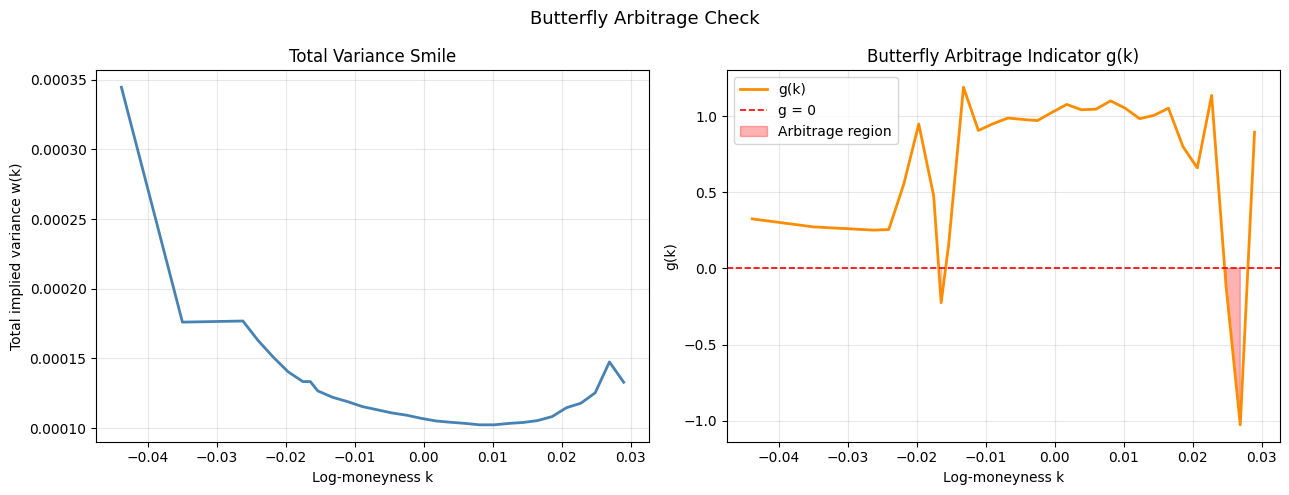

{'is_arbitrage_free': False,
 'min_g': -1.0267720840401826,
 'violations': array([-0.01646342,  0.02483414,  0.02690668]),
 'g': array([ 0.32507391,  0.27248258,  0.25121718,  0.25516777,  0.55328239,
         0.94707244,  0.47572289, -0.22497083,  0.15336929,  1.18919049,
         0.90524601,  0.94976825,  0.98685607,  0.9777021 ,  0.9700648 ,
         1.02443478,  1.07630018,  1.04124665,  1.0450523 ,  1.09942778,
         1.05188307,  0.98248628,  1.00488726,  1.0511653 ,  0.79985657,
         0.65928456,  1.13566969, -0.11100435, -1.02677208,  0.893842  ]),
 'w': array([0.00034468, 0.00017603, 0.00017682, 0.00016295, 0.00015113,
        0.00014046, 0.00013332, 0.00013332, 0.00012665, 0.00012204,
        0.00011896, 0.00011539, 0.00011311, 0.00011083, 0.00010921,
        0.00010693, 0.00010506, 0.00010412, 0.00010332, 0.00010228,
        0.0001023 , 0.0001033 , 0.00010398, 0.00010536, 0.0001082 ,
        0.00011458, 0.0001178 , 0.00012526, 0.00014745, 0.00013284]),
 'k': array([-0.0

In [18]:
log_moneyness_strikes = np.log(np.array(otm_strikes) / df_quote_result["forward"][row_idx])

arbitrage.check_butterfly(log_moneyness_strikes, otm_mid, T=tte, plot=True)

In [19]:
# has_C_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_C" in df_filtered.columns}
# has_P_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_P" in df_filtered.columns}

# for i in range(0, df_filtered.shape[0], 100):
#     row = df_filtered[i]
#     ts = row["ts_ns"][0]
#     tte = float((expiry - ts).total_seconds()) / (365.25 * 24 * 3600)
#     spy_mid = df_spy.filter(pl.col("ts_ns") <= ts)["price"][-1]

#     valid_strikes, valid_ivs = [], []
#     for k in otm_strikes:
#         K_int = int(k)
#         has_C = k in has_C_set
#         has_P = k in has_P_set

#         if has_C and has_P:
#             bid_C, ask_C = row[f"bid_iv_{K_int}_C"][0], row[f"ask_iv_{K_int}_C"][0]
#             bid_P, ask_P = row[f"bid_iv_{K_int}_P"][0], row[f"ask_iv_{K_int}_P"][0]
#             i_bid, i_ask = max(bid_C, bid_P), min(ask_C, ask_P)
#             iv = (
#                 (i_bid + i_ask) / 2
#                 if i_bid <= i_ask
#                 else (
#                     row[f"kalman_iv_{K_int}_C"][0]
#                     if k > spy_mid
#                     else row[f"kalman_iv_{K_int}_P"][0]
#                 )
#             )
#         elif has_C:
#             iv = row[f"kalman_iv_{K_int}_C"][0]
#         elif has_P:
#             iv = row[f"kalman_iv_{K_int}_P"][0]
#         else:
#             continue

#         valid_strikes.append(k)
#         valid_ivs.append(iv)

#     if not arbitrage.check_butterfly(k=valid_strikes, iv=valid_ivs, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]:
#         print(f"Arbitrage detected at index {i} (timestamp {ts})")


In [20]:
# Not log money ness
# from concurrent.futures import ThreadPoolExecutor

# from joblib import Parallel, delayed

# # Single join_asof instead of a per-row filter on df_spy
# sample_df = df_filtered[::10]
# spy_mids = (
#     sample_df.select("ts_ns")
#     .join_asof(df_spy.sort("ts_ns").select("ts_ns", "price"), on="ts_ns", strategy="backward")[
#         "price"
#     ]
#     .to_list()
# )

# has_C_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_C" in df_filtered.columns}
# has_P_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_P" in df_filtered.columns}

# # Convert to plain Python once — avoids polars row access inside threads
# rows = sample_df.to_dicts()
# timestamps = sample_df["ts_ns"].to_list()


# def check_snapshot(i, row, ts, spy_mid, expiry, otm_strikes, has_C_set, has_P_set):
#     tte = float((expiry - ts).total_seconds()) / (365.25 * 24 * 3600)
#     valid_strikes, valid_ivs = [], []
#     for k in otm_strikes:
#         K_int = int(k)
#         has_C, has_P = k in has_C_set, k in has_P_set
#         if has_C and has_P:
#             bid_C, ask_C = row[f"bid_iv_{K_int}_C"], row[f"ask_iv_{K_int}_C"]
#             bid_P, ask_P = row[f"bid_iv_{K_int}_P"], row[f"ask_iv_{K_int}_P"]
#             i_bid, i_ask = max(bid_C, bid_P), min(ask_C, ask_P)
#             iv = (
#                 (i_bid + i_ask) / 2
#                 if i_bid <= i_ask
#                 else (row[f"kalman_iv_{K_int}_C"] if k > spy_mid else row[f"kalman_iv_{K_int}_P"])
#             )
#         elif has_C:
#             iv = row[f"kalman_iv_{K_int}_C"]
#         elif has_P:
#             iv = row[f"kalman_iv_{K_int}_P"]
#         else:
#             continue
#         valid_strikes.append(k)
#         valid_ivs.append(iv)
#     is_free = arbitrage.check_butterfly(k=valid_strikes, iv=valid_ivs, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]
#     return i, ts, is_free


# results = Parallel(n_jobs=-1, backend="loky")(
#     delayed(check_snapshot)(
#         i * 100, rows[i], timestamps[i], spy_mids[i], expiry, otm_strikes, has_C_set, has_P_set
#     )
#     for i in range(len(rows))
# )

# for idx, ts, is_free in results:
#     if not is_free:
#         print(f"Arbitrage detected at index {idx} (timestamp {ts})")

In [21]:
# def check_snapshot(args):
#     i, row, ts, spy_mid = args
#     tte = float((expiry - ts).total_seconds()) / (365.25 * 24 * 3600)
#     valid_strikes, valid_ivs = [], []
#     for k in otm_strikes:
#         K_int = int(k)
#         has_C, has_P = k in has_C_set, k in has_P_set
#         if has_C and has_P:
#             bid_C, ask_C = row[f"bid_iv_{K_int}_C"], row[f"ask_iv_{K_int}_C"]
#             bid_P, ask_P = row[f"bid_iv_{K_int}_P"], row[f"ask_iv_{K_int}_P"]
#             i_bid, i_ask = max(bid_C, bid_P), min(ask_C, ask_P)
#             iv = (
#                 (i_bid + i_ask) / 2
#                 if i_bid <= i_ask
#                 else (row[f"kalman_iv_{K_int}_C"] if k > spy_mid else row[f"kalman_iv_{K_int}_P"])
#             )
#         elif has_C:
#             iv = row[f"kalman_iv_{K_int}_C"]
#         elif has_P:
#             iv = row[f"kalman_iv_{K_int}_P"]
#         else:
#             continue
#         valid_strikes.append(k)
#         valid_ivs.append(iv)
#     is_free = arbitrage.check_butterfly(k=valid_strikes, iv=valid_ivs, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]
#     return i, ts, is_free


# tasks = [(i * 100, rows[i], timestamps[i], spy_mids[i]) for i in range(len(rows))]

# with ThreadPoolExecutor() as executor:
#     for idx, ts, is_free in executor.map(check_snapshot, tasks):
#         if not is_free:
#             print(f"Arbitrage detected at index {idx} (timestamp {ts})")


In [22]:
# for i in range(1, df_filtered.shape[0]):
#     row = df_filtered[i]
#     tte = float((expiry - row["ts_ns"])[0].total_seconds()) / (365.25 * 24 * 3600)
#     mid_ivs_C = [row[f"kalman_iv_{int(k)}_C"][0] for k in strikes_C]
#     if not arbitrage.check_butterfly(k=strikes_C, iv=mid_ivs_C, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]:
#         print(f"Arbitrage detected (calls) at index {i} (timestamp {row['ts_ns'][0]})")
#     mid_ivs_P = [row[f"kalman_iv_{int(k)}_P"][0] for k in strikes_P]
#     if not arbitrage.check_butterfly(k=strikes_P, iv=mid_ivs_P, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]:
#         print(f"Arbitrage detected (puts) at index {i} (timestamp {row['ts_ns'][0]})")

In [23]:
# with dropping quotes and min_trades = 100

# Arbitrage detected at index 32975500 (timestamp 2024-01-03 10:13:05.893184-05:00)
# Arbitrage detected at index 32975600 (timestamp 2024-01-03 10:13:05.893189-05:00)
# Arbitrage detected at index 32975700 (timestamp 2024-01-03 10:13:05.893235-05:00)
# Arbitrage detected at index 32975800 (timestamp 2024-01-03 10:13:05.893451-05:00)
# Arbitrage detected at index 32975900 (timestamp 2024-01-03 10:13:05.893470-05:00)

# Arbitrage detected (calls) at index 329755 (timestamp 2024-01-03 10:13:05.893184-05:00)
# Arbitrage detected (calls) at index 329756 (timestamp 2024-01-03 10:13:05.893189-05:00)
# Arbitrage detected (calls) at index 329757 (timestamp 2024-01-03 10:13:05.893235-05:00)
# Arbitrage detected (calls) at index 329758 (timestamp 2024-01-03 10:13:05.893451-05:00)
# Arbitrage detected (calls) at index 329759 (timestamp 2024-01-03 10:13:05.893470-05:00)
# Arbitrage detected (calls) at index 1503399 (timestamp 2024-01-03 14:20:23.701259-05:00)
# Arbitrage detected (calls) at index 1738694 (timestamp 2024-01-03 14:49:31.390834-05:00)

In [24]:
# row = df_filtered[2192543]
# tte = float((expiry - row["ts_ns"])[0].total_seconds()) / (365.25 * 24 * 3600)
# mid_ivs_C = [row[f"kalman_iv_{int(k)}_C"][0] for k in strikes_C]
# arbitrage.check_butterfly(k=strikes_C, iv=mid_ivs_C, T=tte, plot=True)

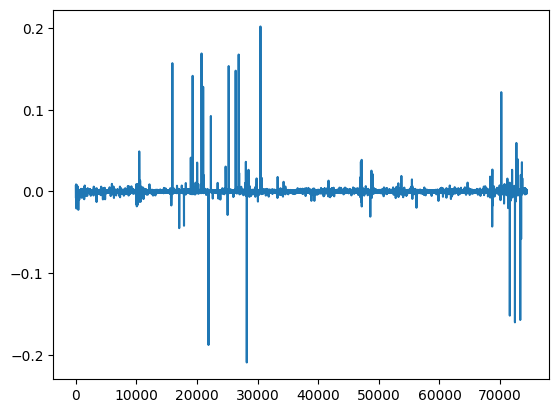

In [25]:
plt.plot(df_trade_result["trade_residual"])

In [26]:
df_trade_result

ts_ns,observed_iv,bid_iv,ask_iv,bid_price,ask_price,kalman_matched,trade_residual,kalman_price,strike,is_call
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
2024-01-03 09:30:00.031 EST,0.130745,0.130745,0.1441,0.08,0.13,0.13765,-0.006905,0.104434,479.0,true
2024-01-03 09:30:00.051 EST,0.142976,0.139489,0.142976,0.07,0.08,0.139871,0.003105,0.071086,480.0,true
2024-01-03 09:30:00.102 EST,0.154323,0.149303,0.151009,0.22,0.23,0.150466,0.003857,0.226927,463.0,false
2024-01-03 09:30:00.102 EST,0.141628,0.141628,0.143618,0.57,0.59,0.141883,-0.000255,0.572613,466.0,false
2024-01-03 09:30:00.111 EST,0.145379,0.140452,0.150292,1.4,1.54,0.13757,0.007809,1.359149,472.0,true
…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:55.650 EST,0.137266,0.136469,0.137266,1.03,1.04,0.136871,0.000395,1.035049,467.0,false
2024-01-03 16:14:56.139 EST,0.13631,0.134822,0.13631,1.38,1.4,0.135455,0.000855,1.388353,468.0,false
2024-01-03 16:14:56.139 EST,0.13631,0.134822,0.13631,1.38,1.4,0.135455,0.000855,1.388353,468.0,false


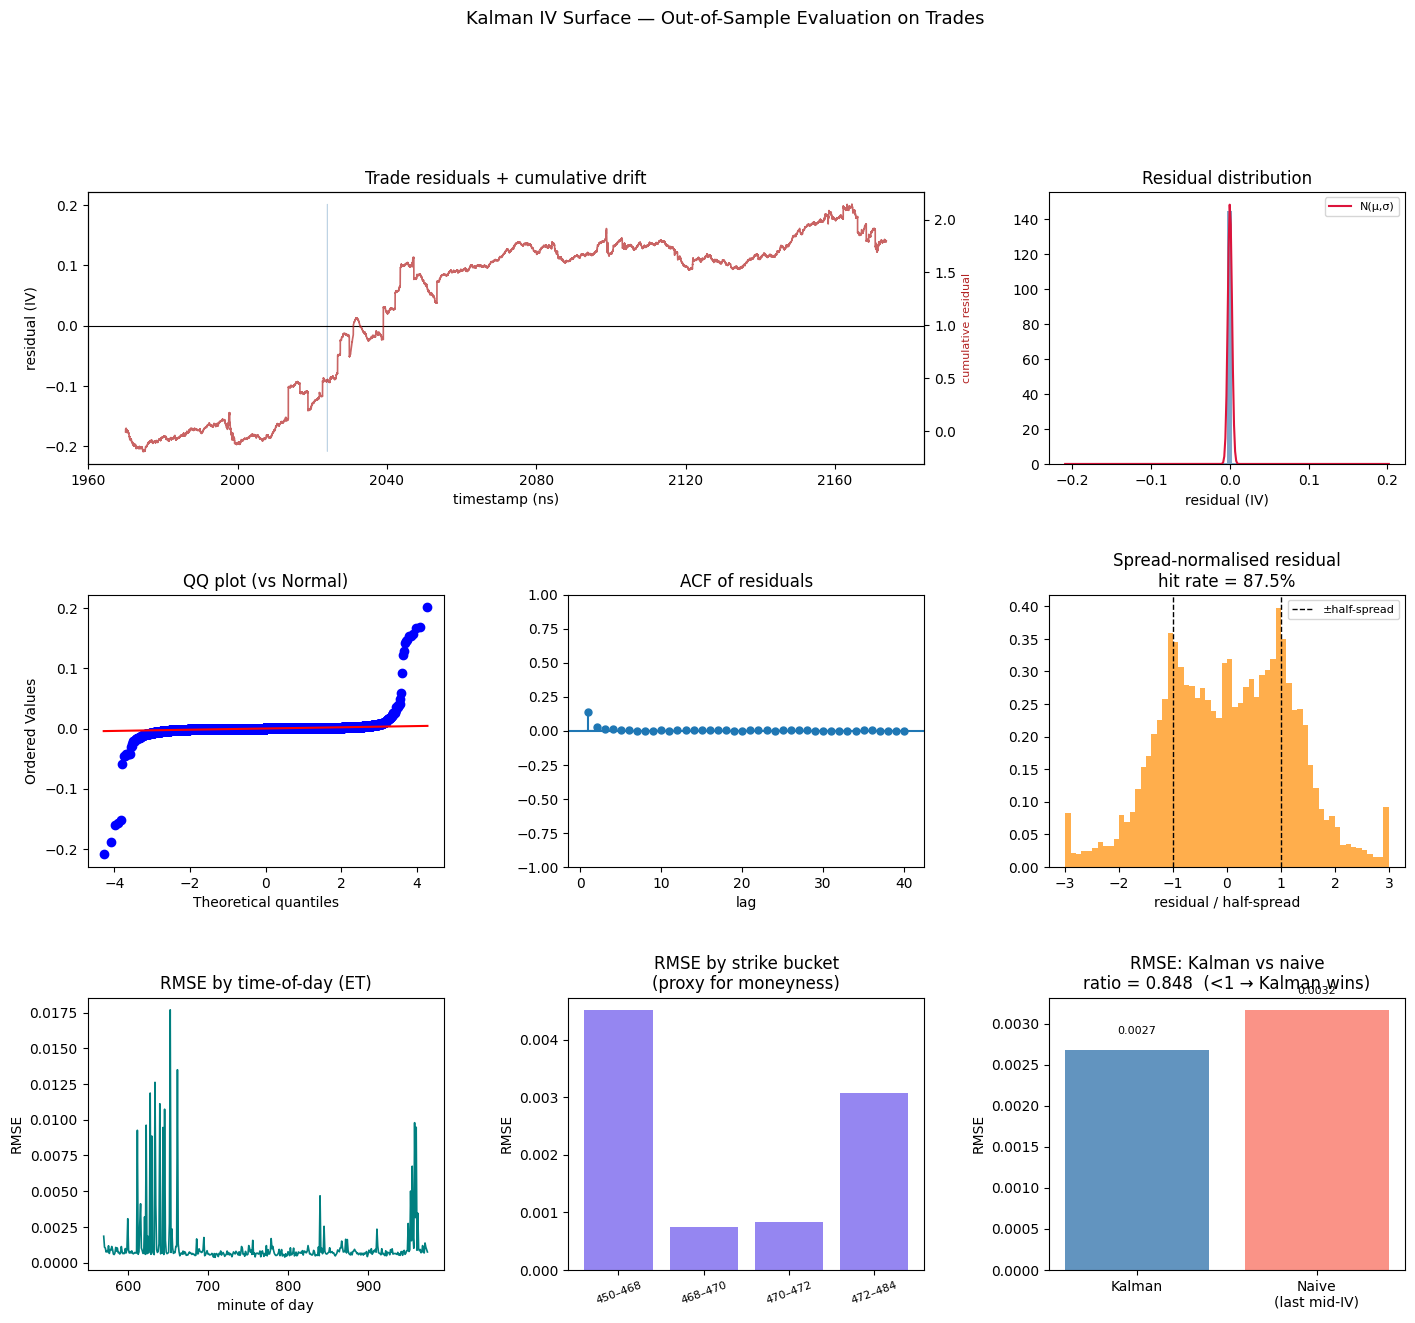

RMSE                 0.00268
MAE                  0.00063
Bias                 0.00002
Hit rate             87.5%
Naive RMSE           0.00316
RMSE ratio           0.848  (<1 = Kalman beats naive)

Ljung-Box (H0: no autocorrelation in residuals):
        lb_stat      lb_pvalue
10  1436.993121  1.020510e-302
20  1447.974398  5.749029e-295


In [27]:
metrics = evaluate_kalman_iv(df_quote_result, df_trade_result)

In [28]:
df_price_surface_wide = utils.synchronize_price_surface(
    df_quote_result.rename({"kalman_price": "observed_price"})
)

In [29]:
df_filtered_price = df_price_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
df_price_surface_long = df_quote_result

strikes_all = sorted(df_price_surface_long["strike"].unique().to_list())
strikes_C = sorted(df_price_surface_long.filter(pl.col("is_call"))["strike"].unique().to_list())
strikes_P = sorted(df_price_surface_long.filter(~pl.col("is_call"))["strike"].unique().to_list())

_, expiry, _ = _u.parse_option_ticker(
    df_tickers.filter(pl.col("ticker").str.contains("C"))["ticker"][0]
)

row_idx = df_filtered_price.shape[0] // 2  # ← change this (0 to df_filtered.shape[0]-1)
snapshot_ts = df_filtered_price["ts_ns"][row_idx]
row = df_price_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"observed_price_{int(k)}_C"][0] for k in strikes_C],
        mode="lines+markers",
        name="calls — kalman mid",
        line=dict(color="royalblue"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"bid_price_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — bid",
        line=dict(color="royalblue", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"ask_price_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — ask",
        line=dict(color="royalblue", dash="dot"),
    )
)

fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"observed_price_{int(k)}_P"][0] for k in strikes_P],
        mode="lines+markers",
        name="puts — kalman mid",
        line=dict(color="firebrick"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"bid_price_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — bid",
        line=dict(color="firebrick", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"ask_price_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — ask",
        line=dict(color="firebrick", dash="dot"),
    )
)

fig.update_layout(
    title=f"price smile (calls + puts) — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

In [30]:
row

ts_ns,bid_price_450_P,ask_price_450_P,observed_price_450_P,bid_price_454_C,ask_price_454_C,observed_price_454_C,bid_price_458_P,ask_price_458_P,observed_price_458_P,bid_price_459_P,ask_price_459_P,observed_price_459_P,bid_price_460_P,ask_price_460_P,observed_price_460_P,bid_price_461_P,ask_price_461_P,observed_price_461_P,bid_price_462_P,ask_price_462_P,observed_price_462_P,bid_price_462_P_right,ask_price_462_P_right,observed_price_462_P_right,bid_price_463_P,ask_price_463_P,observed_price_463_P,bid_price_464_P,ask_price_464_P,observed_price_464_P,bid_price_465_P,ask_price_465_P,observed_price_465_P,bid_price_465_C,ask_price_465_C,observed_price_465_C,…,observed_price_475_P,bid_price_475_C,ask_price_475_C,observed_price_475_C,bid_price_476_P,ask_price_476_P,observed_price_476_P,bid_price_476_C,ask_price_476_C,observed_price_476_C,bid_price_477_P,ask_price_477_P,observed_price_477_P,bid_price_477_C,ask_price_477_C,observed_price_477_C,bid_price_478_C,ask_price_478_C,observed_price_478_C,bid_price_479_C,ask_price_479_C,observed_price_479_C,bid_price_480_C,ask_price_480_C,observed_price_480_C,bid_price_481_C,ask_price_481_C,observed_price_481_C,bid_price_482_C,ask_price_482_C,observed_price_482_C,bid_price_483_C,ask_price_483_C,observed_price_483_C,bid_price_484_C,ask_price_484_C,observed_price_484_C
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 12:56:18.293149440 EST,0.02,0.03,0.025321,16.15,16.5,16.327405,0.05,0.06,0.054145,0.06,0.07,0.064366,0.08,0.09,0.08375,0.1,0.11,0.10404,0.14,0.15,0.144884,0.16,0.17,0.165931,0.19,0.2,0.197381,0.27,0.28,0.275827,0.39,0.4,0.393679,5.67,5.75,5.710033,…,5.143869,0.41,0.42,0.415307,6.0,6.11,6.055009,0.27,0.28,0.276207,6.96,7.08,7.020028,0.18,0.19,0.18431,0.11,0.12,0.117356,0.07,0.08,0.076875,0.05,0.06,0.054761,0.03,0.04,0.036142,0.02,0.03,0.026211,0.02,0.03,0.022166,0.02,0.03,0.02204


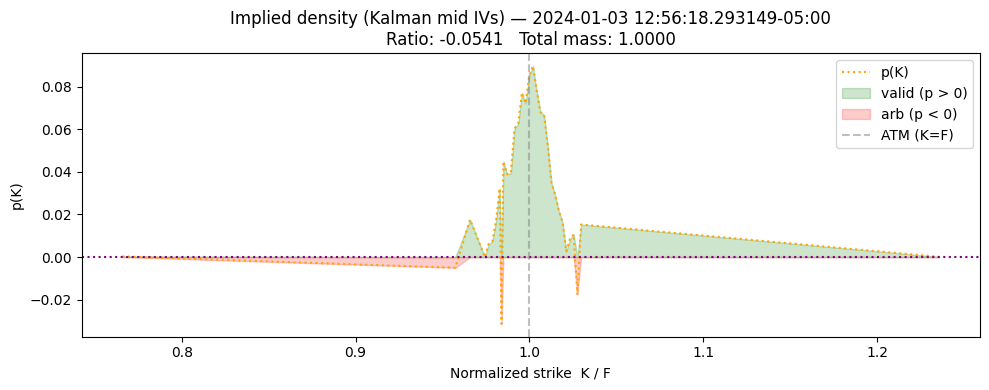

In [31]:
# ── Implied probability density from Kalman IVs (Breeden-Litzenberger) ──────
# Depends on: snapshot_ts, expiry, spy_mid, otm_strikes, otm_mid
import scipy.stats as stats


def _bs_call(F, K, T, sigma):
    """Black-Scholes call price with r=0 (forward = spot)."""
    if sigma <= 0 or T <= 0:
        return float(max(F - K, 0.0))
    d1 = (np.log(F / K) + 0.5 * sigma**2 * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return float(F * stats.norm.cdf(d1) - K * stats.norm.cdf(d2))


F = spy_mid  # forward ≈ spot (r=0)
tte = float((expiry - snapshot_ts).total_seconds()) / (365.25 * 24 * 3600)

# Filter strikes with a valid Kalman mid IV
valid = [(k, iv) for k, iv in zip(otm_strikes, otm_mid) if iv is not None]
strikes = np.array([v[0] for v in valid])
ivs = np.array([v[1] for v in valid])

# Normalize to pure space: kappa = K/F, C_pure = C_BS / F
pure_strikes = strikes / F
pure_mids = np.array([_bs_call(F, k, tte, iv) / F for k, iv in zip(strikes, ivs)])

# Extend strike grid with boundary conditions
strikesx = np.zeros(len(pure_strikes) + 2)
strikesx[1:-1] = pure_strikes
strikesx[0] = pure_strikes[0] * 0.8  # far left (deep ITM)
strikesx[-1] = pure_strikes[-1] * 1.2  # far right (deep OTM)

midx = np.zeros_like(strikesx)
midx[1:-1] = pure_mids
midx[0] = 1.0 - strikesx[0]  # deep ITM call ≈ F - K → 1 - kappa
midx[-1] = 0.0  # deep OTM call → 0

# Breeden-Litzenberger: d²C/dK² = risk-neutral density
dCdK = np.diff(midx, prepend=1.0) / np.diff(strikesx, prepend=0.0)
p = np.diff(dCdK, append=0.0)

ratio = np.sum(p[p < 0.0])  # negative mass = butterfly arbitrage
total = np.sum(p)  # should be ≈ 1

fig, ax = plt.subplots(figsize=(10, 4))
ax.set_title(
    f"Implied density (Kalman mid IVs) — {snapshot_ts}\nRatio: {ratio:.4f}   Total mass: {total:.4f}"
)
ax.set_xlabel("Normalized strike  K / F")
ax.set_ylabel("p(K)")
ax.plot(strikesx, p, ":", color="orange", label="p(K)")
ax.fill_between(strikesx, 0, np.clip(p, 0, None), color="green", alpha=0.2, label="valid (p > 0)")
ax.fill_between(strikesx, np.clip(p, None, 0), 0, color="red", alpha=0.2, label="arb (p < 0)")
ax.axhline(0, color="purple", linestyle=":")
ax.axvline(1.0, color="gray", linestyle="--", alpha=0.5, label="ATM (K=F)")
ax.legend()
plt.tight_layout()
plt.show()